In [1]:
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (
    PROJECT_ROOT / "Processed Data" / "ev_charging_cleaned.csv"
)

MODEL_PATH = (
    PROJECT_ROOT / "models" / "xgboost_classification_model.pkl"
)

file_path = DATA_PATH

df = pd.read_csv(file_path)

df['StartDatetime'] = pd.to_datetime(df['StartDatetime'])

print(df.shape)
print(df.dtypes)

(72826, 18)
UserID                          int64
ChargerID                       int64
ChargerCompany                  int64
Location                          str
ChargerType                     int64
StartDay                          str
StartTime                         str
EndDay                            str
EndTime                           str
StartDatetime          datetime64[us]
EndDatetime                       str
Duration                        int64
Demand                        float64
Calculated_Duration           float64
Duration_Difference           float64
Duration_Group                    str
Hour                            int64
DayOfWeek                       int64
dtype: object


In [2]:
median_demand = df['Demand'].median()

print("Median Demand:", median_demand)

Median Demand: 14.1


In [3]:
#setting the demand category
median_demand = df['Demand'].median()

df['Demand_Category'] = df['Demand'].apply(
    lambda x: 'High Demand' if x >= median_demand else 'Normal Demand'
)

print(df[['Demand', 'Demand_Category']].head(10))

   Demand Demand_Category
0   20.36     High Demand
1   10.19   Normal Demand
2    6.78   Normal Demand
3   37.65     High Demand
4   33.81     High Demand
5    8.17   Normal Demand
6    6.38   Normal Demand
7   55.17     High Demand
8    6.68   Normal Demand
9   12.57   Normal Demand


In [4]:
# check the actual counts of category

print("Class Counts:")
print(df['Demand_Category'].value_counts())

print("\nClass Percentages:")
print(
    (df['Demand_Category'].value_counts(normalize=True) * 100).round(2)
)

Class Counts:
Demand_Category
High Demand      36439
Normal Demand    36387
Name: count, dtype: int64

Class Percentages:
Demand_Category
High Demand      50.04
Normal Demand    49.96
Name: proportion, dtype: float64


The classification target was nearly perfectly balanced, with 50.04% High Demand and 49.96% Normal Demand. Therefore, no oversampling or class-balancing technique was required

In [5]:
#Creating features

df['Day'] = df['StartDatetime'].dt.day
df['Month'] = df['StartDatetime'].dt.month
df['Quarter'] = df['StartDatetime'].dt.quarter

df['IsWeekend'] = df['DayOfWeek'].isin([5, 6]).astype(int)

def get_time_of_day(hour):
    if 0 <= hour < 6:
        return 'Night'
    elif 6 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 17:
        return 'Afternoon'
    elif 17 <= hour < 21:
        return 'Evening'
    else:
        return 'Night'


df['TimeOfDay'] = df['Hour'].apply(get_time_of_day)

In [6]:
#define features

features = [
    'Hour',
    'Day',
    'DayOfWeek',
    'Month',
    'Quarter',
    'IsWeekend',
    'TimeOfDay',
    'Location',
    'ChargerType',
    'ChargerCompany',
    'Calculated_Duration'
]

X = df[features]
y = df['Demand_Category']

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget:")
print(y.head())

X shape: (72826, 11)
y shape: (72826,)

Features:
['Hour', 'Day', 'DayOfWeek', 'Month', 'Quarter', 'IsWeekend', 'TimeOfDay', 'Location', 'ChargerType', 'ChargerCompany', 'Calculated_Duration']

Target:
0      High Demand
1    Normal Demand
2    Normal Demand
3      High Demand
4      High Demand
Name: Demand_Category, dtype: str


In [7]:
#split the data

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (58260, 11)
X_test: (14566, 11)
y_train: (58260,)
y_test: (14566,)


In [9]:
#preprocessing

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = ['Location', 'TimeOfDay']

numeric_features = [
    'Hour',
    'Day',
    'DayOfWeek',
    'Month',
    'Quarter',
    'IsWeekend',
    'ChargerType',
    'ChargerCompany',
    'Calculated_Duration'
]

preprocessor = ColumnTransformer([
    (
        'categorical',
        OneHotEncoder(handle_unknown='ignore'),
        categorical_features
    ),
    (
        'numeric',
        StandardScaler(),
        numeric_features
    )
])

In [10]:
# fit the model

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

#prediction
y_pred_logistic = logistic_model.predict(X_test)

print(y_pred_logistic[:10])

['Normal Demand' 'Normal Demand' 'High Demand' 'High Demand' 'High Demand'
 'Normal Demand' 'High Demand' 'Normal Demand' 'High Demand'
 'Normal Demand']


In [11]:
#Evaluate the model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred_logistic)

precision = precision_score(
    y_test,
    y_pred_logistic,
    pos_label='High Demand'
)

recall = recall_score(
    y_test,
    y_pred_logistic,
    pos_label='High Demand'
)

f1 = f1_score(
    y_test,
    y_pred_logistic,
    pos_label='High Demand'
)

high_demand_index = list(logistic_model.classes_).index('High Demand')

y_prob_logistic = logistic_model.predict_proba(X_test)[:, high_demand_index]

roc_auc = roc_auc_score(
    (y_test == 'High Demand').astype(int),
    y_prob_logistic
)

print("ROC-AUC:", roc_auc)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("ROC-AUC  :", roc_auc)

ROC-AUC: 0.8997071079285301
Accuracy : 0.8263078401757518
Precision: 0.8096043727225404
Recall   : 0.8535949506037321
F1 Score : 0.8310179000801496
ROC-AUC  : 0.8997071079285301


In [12]:
#Decision tree classifier

from sklearn.tree import DecisionTreeClassifier

decision_tree_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(
        random_state=42
    ))
])

decision_tree_model.fit(X_train, y_train)

y_pred_dt = decision_tree_model.predict(X_test)

accuracy_dt = accuracy_score(y_test, y_pred_dt)

precision_dt = precision_score(
    y_test,
    y_pred_dt,
    pos_label='High Demand'
)

recall_dt = recall_score(
    y_test,
    y_pred_dt,
    pos_label='High Demand'
)

f1_dt = f1_score(
    y_test,
    y_pred_dt,
    pos_label='High Demand'
)

high_demand_index = list(
    decision_tree_model.classes_
).index('High Demand')

y_prob_dt = decision_tree_model.predict_proba(X_test)[:, high_demand_index]

roc_auc_dt = roc_auc_score(
    (y_test == 'High Demand').astype(int),
    y_prob_dt
)

print("Accuracy :", accuracy_dt)
print("Precision:", precision_dt)
print("Recall   :", recall_dt)
print("F1 Score :", f1_dt)
print("ROC-AUC  :", roc_auc_dt)

Accuracy : 0.8477275847864891
Precision: 0.8478320526893524
Recall   : 0.8478320526893524
F1 Score : 0.8478320526893524
ROC-AUC  : 0.8479411453521114


In [13]:
#Random Forest

from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

y_pred_rf = random_forest_model.predict(X_test)

#Evaluate

accuracy_rf = accuracy_score(y_test, y_pred_rf)

precision_rf = precision_score(
    y_test, y_pred_rf, pos_label='High Demand'
)

recall_rf = recall_score(
    y_test, y_pred_rf, pos_label='High Demand'
)

f1_rf = f1_score(
    y_test, y_pred_rf, pos_label='High Demand'
)

high_demand_index = list(
    random_forest_model.classes_
).index('High Demand')

y_prob_rf = random_forest_model.predict_proba(X_test)[:, high_demand_index]

roc_auc_rf = roc_auc_score(
    (y_test == 'High Demand').astype(int),
    y_prob_rf
)

print("Accuracy :", accuracy_rf)
print("Precision:", precision_rf)
print("Recall   :", recall_rf)
print("F1 Score :", f1_rf)
print("ROC-AUC  :", roc_auc_rf)

Accuracy : 0.8937251132774955
Precision: 0.8676658980271585
Recall   : 0.9293358946212953
F1 Score : 0.8974426924605804
ROC-AUC  : 0.951631765309887


In [14]:
#KNN
from sklearn.neighbors import KNeighborsClassifier

knn_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)

#Evaluate

accuracy_knn = accuracy_score(y_test, y_pred_knn)

precision_knn = precision_score(
    y_test, y_pred_knn, pos_label='High Demand'
)

recall_knn = recall_score(
    y_test, y_pred_knn, pos_label='High Demand'
)

f1_knn = f1_score(
    y_test, y_pred_knn, pos_label='High Demand'
)

high_demand_index = list(
    knn_model.classes_
).index('High Demand')

y_prob_knn = knn_model.predict_proba(X_test)[:, high_demand_index]

roc_auc_knn = roc_auc_score(
    (y_test == 'High Demand').astype(int),
    y_prob_knn
)

print("Accuracy :", accuracy_knn)
print("Precision:", precision_knn)
print("Recall   :", recall_knn)
print("F1 Score :", f1_knn)
print("ROC-AUC  :", roc_auc_knn)

Accuracy : 0.7991898942743375
Precision: 0.791293897716651
Recall   : 0.8131174533479693
F1 Score : 0.8020572511335183
ROC-AUC  : 0.8763975040639445


In [ ]:
#SVM

from sklearn.svm import SVC

svm_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', SVC(
        kernel='linear',
        random_state=42
    ))
])

svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

accuracy_svm = accuracy_score(y_test, y_pred_svm)

precision_svm = precision_score(
    y_test, y_pred_svm, pos_label='High Demand'
)

recall_svm = recall_score(
    y_test, y_pred_svm, pos_label='High Demand'
)

f1_svm = f1_score(
    y_test, y_pred_svm, pos_label='High Demand'
)

y_score_svm = -svm_model.decision_function(X_test)

roc_auc_svm = roc_auc_score(
    (y_test == 'High Demand').astype(int),
    y_score_svm
)


print("Accuracy :", accuracy_svm)
print("Precision:", precision_svm)
print("Recall   :", recall_svm)
print("F1 Score :", f1_svm)
print("ROC-AUC  :", roc_auc_svm)

Accuracy : 0.8267197583413428
Precision: 0.7826293308020883
Recall   : 0.9050493962678375
F1 Score : 0.8393993382540087
ROC-AUC  : 0.10451236399850503


In [16]:
y_score_svm = -svm_model.decision_function(X_test)

roc_auc_svm = roc_auc_score(
    (y_test == 'High Demand').astype(int),
    y_score_svm
)

print("ROC-AUC:", roc_auc_svm)

ROC-AUC: 0.895487636001495


In [18]:
#XG Boost
y_xgb = y.map({
    'Normal Demand': 0,
    'High Demand': 1
})

print(y_xgb.value_counts())

y_xgb_train = y_xgb.loc[X_train.index]
y_xgb_test = y_xgb.loc[X_test.index]

from xgboost import XGBClassifier

xgb_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBClassifier(
        n_estimators=100,
        random_state=42,
        eval_metric='logloss'
    ))
])

xgb_model.fit(X_train, y_xgb_train)

y_pred_xgb = xgb_model.predict(X_test)

y_pred_xgb_labels = pd.Series(
    y_pred_xgb,
    index=X_test.index
).map({
    0: 'Normal Demand',
    1: 'High Demand'
})

accuracy_xgb = accuracy_score(y_test, y_pred_xgb_labels)

precision_xgb = precision_score(
    y_test,
    y_pred_xgb_labels,
    pos_label='High Demand'
)

recall_xgb = recall_score(
    y_test,
    y_pred_xgb_labels,
    pos_label='High Demand'
)

f1_xgb = f1_score(
    y_test,
    y_pred_xgb_labels,
    pos_label='High Demand'
)

y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

roc_auc_xgb = roc_auc_score(
    y_xgb_test,
    y_prob_xgb
)

print("Accuracy :", accuracy_xgb)
print("Precision:", precision_xgb)
print("Recall   :", recall_xgb)
print("F1 Score :", f1_xgb)
print("ROC-AUC  :", roc_auc_xgb)

Demand_Category
1    36439
0    36387
Name: count, dtype: int64
Accuracy : 0.8965398874090348
Precision: 0.8695818948983506
Recall   : 0.9331778265642151
F1 Score : 0.9002581242967768
ROC-AUC  : 0.9571526477551852


In [19]:
#Light gbm

from lightgbm import LGBMClassifier

lgbm_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LGBMClassifier(
        n_estimators=100,
        random_state=42,
        verbosity=-1
    ))
])

lgbm_model.fit(X_train, y_xgb_train)

y_pred_lgbm = lgbm_model.predict(X_test)

#convert back
y_pred_lgbm_labels = pd.Series(
    y_pred_lgbm,
    index=X_test.index
).map({
    0: 'Normal Demand',
    1: 'High Demand'
})

accuracy_lgbm = accuracy_score(y_test, y_pred_lgbm_labels)

precision_lgbm = precision_score(
    y_test,
    y_pred_lgbm_labels,
    pos_label='High Demand'
)

recall_lgbm = recall_score(
    y_test,
    y_pred_lgbm_labels,
    pos_label='High Demand'
)

f1_lgbm = f1_score(
    y_test,
    y_pred_lgbm_labels,
    pos_label='High Demand'
)

y_prob_lgbm = lgbm_model.predict_proba(X_test)[:, 1]

roc_auc_lgbm = roc_auc_score(
    y_xgb_test,
    y_prob_lgbm
)

print("Accuracy :", accuracy_lgbm)
print("Precision:", precision_lgbm)
print("Recall   :", recall_lgbm)
print("F1 Score :", f1_lgbm)
print("ROC-AUC  :", roc_auc_lgbm)

Accuracy : 0.8944802965810792
Precision: 0.8643101482326112
Recall   : 0.936059275521405
F1 Score : 0.8987550227257757
ROC-AUC  : 0.9563819575346841


"LightGBM achieved the highest Recall, meaning it identified slightly more High Demand sessions. However, XGBoost achieved the best Accuracy, Precision, F1-score, and ROC-AUC, giving it the strongest overall classification performance. Therefore, I selected XGBoost as the final classification model."

In [20]:
# Get feature names after preprocessing
feature_names = xgb_model.named_steps['preprocessor'].get_feature_names_out()

# Get feature importance from XGBoost
importance_values = xgb_model.named_steps['model'].feature_importances_

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance_values
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 15 features
feature_importance.head(15)

,Feature,Importance
24,numeric__ChargerType,0.707056
26,numeric__Calculated_Duration,0.073546
25,numeric__ChargerCompany,0.052262
11,categorical__Location_resort,0.017123
6,categorical__Location_hotel,0.012770
7,categorical__Location_market,0.011736
1,categorical__Location_apartment,0.011373
4,categorical__Location_company,0.010914
0,categorical__Location_accommodation,0.010590
17,categorical__TimeOfDay_Night,0.009209


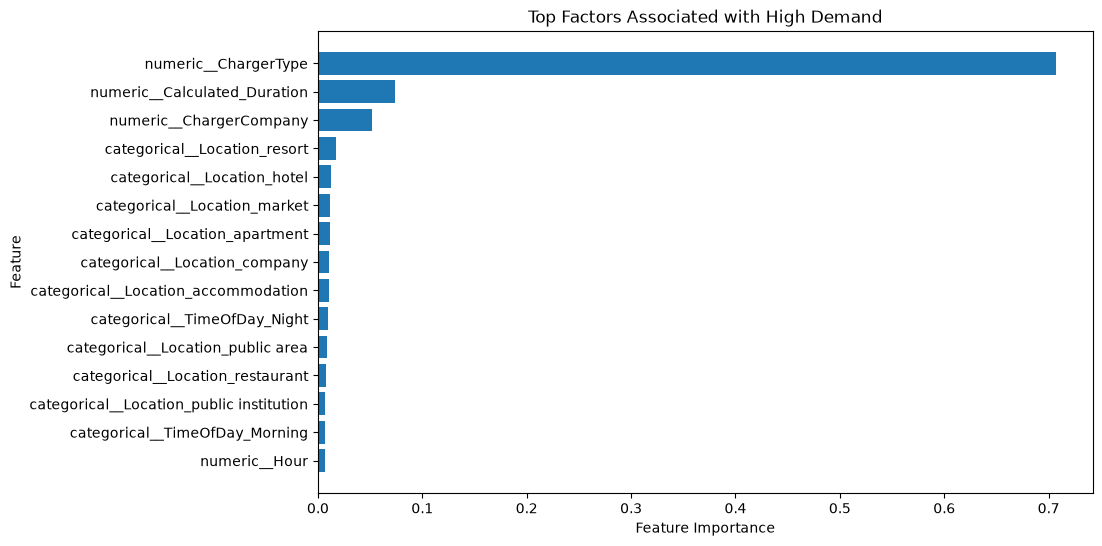

In [21]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features['Feature'][::-1],
    top_features['Importance'][::-1]
)

plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top Factors Associated with High Demand')
plt.show()

XGBoost identified ChargerType as the most important predictive factor for distinguishing High Demand from Normal Demand sessions. Calculated charging duration and ChargerCompany were the next most important numerical factors, while location and time-related features had comparatively smaller individual contributions.

In [ ]:
#save the model

import pickle

model_path = MODEL_PATH

with open(model_path, 'wb') as file:
    pickle.dump(xgb_model, file)

print("XGBoost classification model saved successfully.")

XGBoost classification model saved successfully.


In [23]:
#load the model
with open(model_path, 'rb') as file:
    loaded_xgb_model = pickle.load(file)

print("XGBoost classification model loaded successfully.")

XGBoost classification model loaded successfully.


In [24]:
#test the model
loaded_predictions = loaded_xgb_model.predict(X_test)

print("Predictions from loaded model:")
print(loaded_predictions[:10])

Predictions from loaded model:
[0 0 1 1 1 0 1 0 1 0]


In [25]:
original_predictions = xgb_model.predict(X_test)

print(
    "Predictions match:",
    (original_predictions == loaded_predictions).all()
)

Predictions match: True
